# Bike Sharing Case Study: Understanding the Data

**CEO's question:** *"Riders keep complaining they can't find a bike when they need one. Meanwhile I see bikes sitting unused all over the city. Should we just buy more bikes?"*

This notebook covers the first step of the case: **understanding the dataset, checking its quality, and exploring it with graphs.**

## 1. What the dataset is

The **UCI Bike Sharing dataset**: two years (2011–2012) of rentals from **Capital Bikeshare, Washington D.C.**, aggregated and joined with weather and calendar information.

| File | Grain | Rows |
|---|---|---|
| `day.csv` | one row per day | 731 |
| `hour.csv` | one row per hour | 17,379 |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.titleweight"] = "bold"

In [2]:
df1 = pd.read_csv("Dataset/day.csv")
df2 = pd.read_csv("Dataset/hour.csv")

# Readable names: day-level and hour-level data
day, hour = df1.copy(), df2.copy()
print("day :", day.shape)
print("hour:", hour.shape)

day : (731, 16)
hour: (17379, 17)


In [3]:
df1.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Columns

**Time and calendar**
- `instant`: row index (no information, dropped)
- `dteday`: date; `yr` (0 = 2011, 1 = 2012); `mnth` (1–12); `hr` (0–23, hourly file only); `weekday` (0 = Sunday … 6 = Saturday)
- `season`: the readme says 1 = spring, 2 = summer, 3 = fall, 4 = winter, but the dates show **1 = winter, 2 = spring, 3 = summer, 4 = fall** (see 3d)
- `holiday`: public holiday flag; `workingday`: 1 if neither weekend nor holiday

**Weather**
- `weathersit`: 1 = clear, 2 = mist/cloudy, 3 = light rain/snow, 4 = heavy rain/snow/fog
- `temp`, `atemp`, `hum`, `windspeed`: **already scaled to 0–1**. Real values = value × max: temp × 41 °C, feels-like × 50 °C, humidity × 100 %, wind × 67 km/h

**Targets**
- `casual`: rentals by non-members
- `registered`: rentals by members
- `cnt` = `casual` + `registered`: total rentals

## 3. Data quality checks

In [4]:
for name, df in [("day", day), ("hour", hour)]:
    print(f"--- {name} ---")
    print("missing values  :", df.isna().sum().sum())
    print("duplicate rows  :", df.duplicated().sum())
    print("cnt == cas + reg:", (df.cnt == df.casual + df.registered).all())
    print("date range      :", df.dteday.min(), "->", df.dteday.max())

hour.describe().T.round(2)

--- day ---
missing values  : 0
duplicate rows  : 0
cnt == cas + reg: True
date range      : 2011-01-01 -> 2012-12-31
--- hour ---
missing values  : 0
duplicate rows  : 0
cnt == cas + reg: True
date range      : 2011-01-01 -> 2012-12-31


,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.00,5017.03,1.00,4345.50,8690.00,13034.50,17379.00
season,17379.0,2.50,1.11,1.00,2.00,3.00,3.00,4.00
yr,17379.0,0.50,0.50,0.00,0.00,1.00,1.00,1.00
mnth,17379.0,6.54,3.44,1.00,4.00,7.00,10.00,12.00
hr,17379.0,11.55,6.91,0.00,6.00,12.00,18.00,23.00
holiday,17379.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
weekday,17379.0,3.00,2.01,0.00,1.00,3.00,5.00,6.00
workingday,17379.0,0.68,0.47,0.00,0.00,1.00,1.00,1.00
weathersit,17379.0,1.43,0.64,1.00,1.00,1.00,2.00,4.00
temp,17379.0,0.50,0.19,0.02,0.34,0.50,0.66,1.00


### 3a. Missing hours
731 days × 24 hours = 17,544 expected rows, but the hourly file has 17,379, so **165 hours are absent**. Hours with zero rentals were not recorded, so most gaps are between 02:00 and 05:00. The rest are outages: the worst days are 2012-10-29/30 (Hurricane Sandy) and a few winter-storm days in January 2011.

missing hours: 165


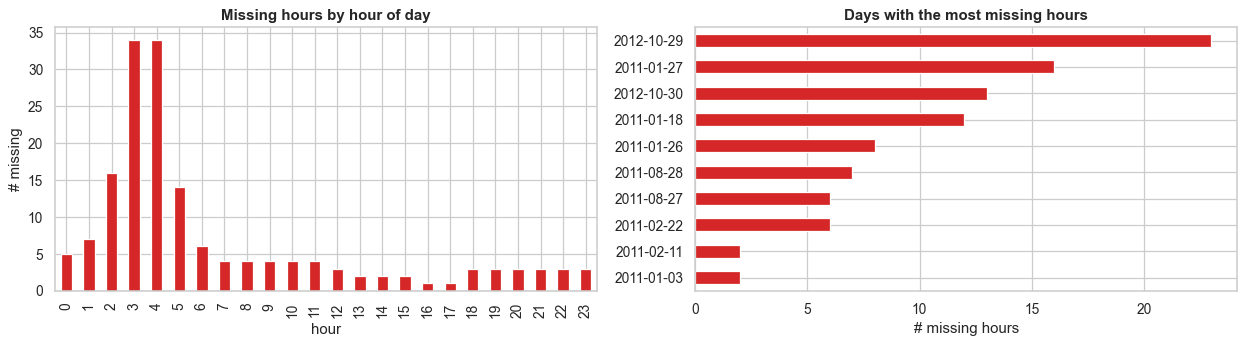

In [5]:
hour["dteday"] = pd.to_datetime(hour["dteday"])
day["dteday"] = pd.to_datetime(day["dteday"])

full = pd.MultiIndex.from_product([day.dteday, range(24)], names=["dteday", "hr"])
missing = full.difference(hour.set_index(["dteday", "hr"]).index).to_frame(index=False)
print("missing hours:", len(missing))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
missing.hr.value_counts().reindex(range(24), fill_value=0).plot.bar(ax=axes[0], color="tab:red")
axes[0].set(title="Missing hours by hour of day", xlabel="hour", ylabel="# missing")
per_day = missing.groupby("dteday").size().sort_values(ascending=False).head(10)
per_day.index = per_day.index.strftime("%Y-%m-%d")
per_day.plot.barh(ax=axes[1], color="tab:red")
axes[1].set(title="Days with the most missing hours", xlabel="# missing hours", ylabel="")
axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

### 3b. Suspicious zeros in weather
- `windspeed == 0` appears far too often. It is almost certainly a missing reading, not calm air, so it should be imputed or flagged.
- `hum == 0` is physically impossible (a sensor gap).

windspeed == 0: 2180 rows
hum == 0      : 22 rows


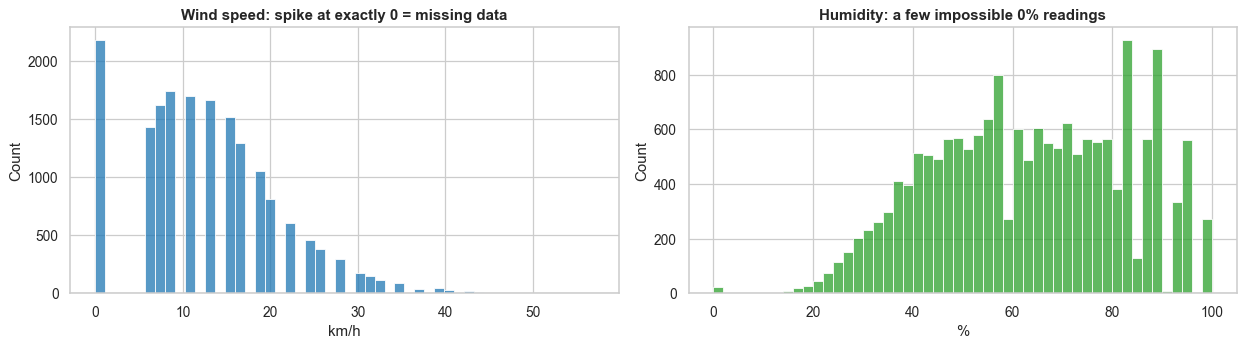

In [6]:
print("windspeed == 0:", (hour.windspeed == 0).sum(), "rows")
print("hum == 0      :", (hour.hum == 0).sum(), "rows")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(hour.windspeed * 67, bins=50, ax=axes[0], color="tab:blue")
axes[0].set(title="Wind speed: spike at exactly 0 = missing data", xlabel="km/h")
sns.histplot(hour.hum * 100, bins=50, ax=axes[1], color="tab:green")
axes[1].set(title="Humidity: a few impossible 0% readings", xlabel="%")
plt.tight_layout(); plt.show()

### 3c. Real-world anomalies
The lowest days line up with real events. 2012-10-29 is **Hurricane Sandy** (22 rentals all day). Several low days fall around Christmas.

In [7]:
day.nsmallest(8, "cnt")[["dteday", "cnt", "weathersit", "holiday", "workingday"]]

,dteday,cnt,weathersit,holiday,workingday
667,2012-10-29,22,3,0,1
26,2011-01-27,431,1,0,1
725,2012-12-26,441,3,0,1
25,2011-01-26,506,3,0,1
64,2011-03-06,605,2,0,0
68,2011-03-10,623,3,0,1
301,2011-10-29,627,3,0,0
17,2011-01-18,683,2,0,1


### 3d. Season codes are mislabelled in the readme
The readme says `season` 1 = spring. But a month × season table shows code 1 covers **21 Dec – 20 Mar**, which is winter. The codes follow astronomical seasons shifted by one, so the correct labels are **1 = winter, 2 = spring, 3 = summer, 4 = fall**. Using the readme labels would make "spring" look like the weakest season when it's really winter.

In [8]:
pd.crosstab(day.mnth, day.season).rename_axis(index="month", columns="season code")

season code,1,2,3,4
month,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


## 4. Feature preparation
Convert the scaled weather values back to real units and add readable labels for charts.

In [9]:
season_map = {1: "Winter", 2: "Spring", 3: "Summer", 4: "Fall"}  # corrected labels, see 3d
weather_map = {1: "Clear", 2: "Mist/Cloudy", 3: "Light rain/snow", 4: "Heavy rain/snow"}

for df in (day, hour):
    df["temp_c"] = df.temp * 41
    df["atemp_c"] = df.atemp * 50
    df["hum_pct"] = df.hum * 100
    df["wind_kmh"] = df.windspeed * 67
    df["season_name"] = df.season.map(season_map)
    df["weather"] = df.weathersit.map(weather_map)
    df["year"] = df.yr.map({0: 2011, 1: 2012})
    df["day_type"] = df.workingday.map({1: "Working day", 0: "Weekend/holiday"})

hour[["temp_c", "atemp_c", "hum_pct", "wind_kmh"]].describe().round(1)

,temp_c,atemp_c,hum_pct,wind_kmh
count,17379.0,17379.0,17379.0,17379.0
mean,20.4,23.8,62.7,12.7
std,7.9,8.6,19.3,8.2
min,0.8,0.0,0.0,0.0
25%,13.9,16.7,48.0,7.0
50%,20.5,24.2,63.0,13.0
75%,27.1,31.1,78.0,17.0
max,41.0,50.0,100.0,57.0


## 5. Exploring demand

### 5a. Demand over time
Rentals grew strongly from 2011 to 2012 and follow a clear seasonal cycle (low in winter, high in summer and fall).

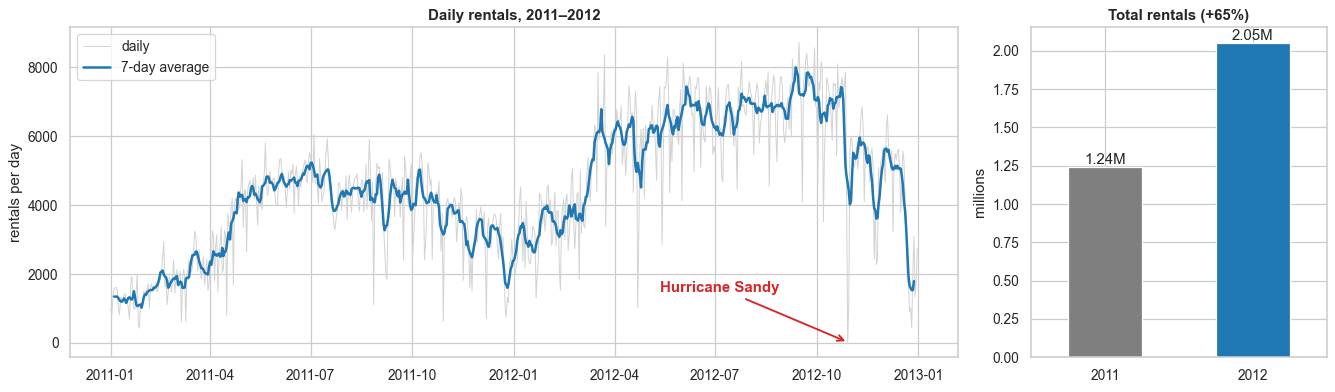

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})
ax = axes[0]
ax.plot(day.dteday, day.cnt, color="lightgray", lw=0.8, label="daily")
ax.plot(day.dteday, day.cnt.rolling(7, center=True).mean(), color="tab:blue", lw=2, label="7-day average")
sandy = day.loc[day.cnt.idxmin()]
ax.annotate("Hurricane Sandy", (sandy.dteday, sandy.cnt), xytext=(-150, 40),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.5),
            color="tab:red", fontweight="bold")
ax.set(title="Daily rentals, 2011–2012", ylabel="rentals per day"); ax.legend()

yearly = day.groupby("year").cnt.sum() / 1e6
yearly.plot.bar(ax=axes[1], color=["tab:gray", "tab:blue"], rot=0)
for i, v in enumerate(yearly):
    axes[1].text(i, v, f"{v:.2f}M", ha="center", va="bottom")
axes[1].set(title=f"Total rentals (+{yearly[2012] / yearly[2011] - 1:.0%})", ylabel="millions", xlabel="")
plt.tight_layout(); plt.show()

### 5b. Who rides: members vs casual riders
Registered members make up about **81 %** of rentals. Casual riders are more seasonal and weekend-heavy.

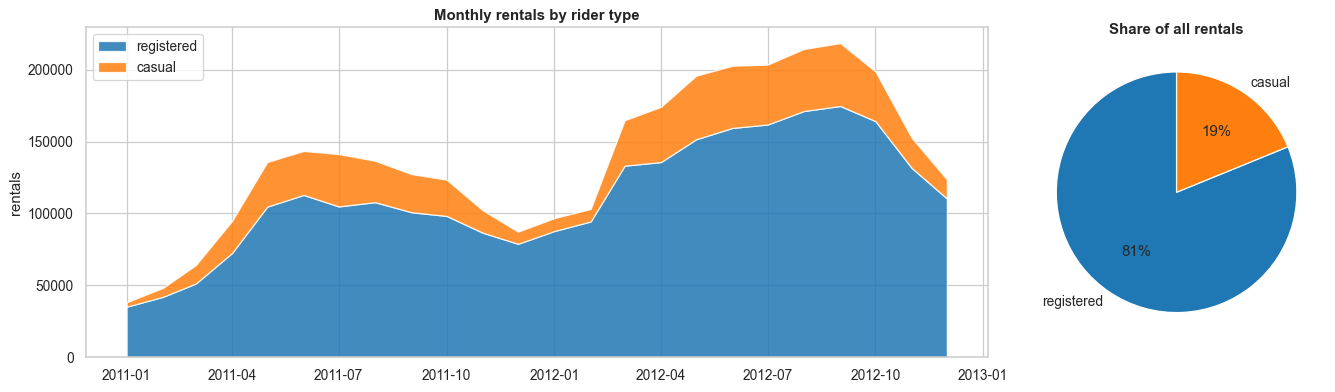

In [11]:
monthly = day.set_index("dteday")[["registered", "casual"]].resample("MS").sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [3, 1]})
axes[0].stackplot(monthly.index, monthly.registered, monthly.casual,
                  labels=["registered", "casual"], colors=["tab:blue", "tab:orange"], alpha=0.85)
axes[0].set(title="Monthly rentals by rider type", ylabel="rentals"); axes[0].legend(loc="upper left")

share = hour[["registered", "casual"]].sum()
axes[1].pie(share, labels=share.index, autopct="%1.0f%%", colors=["tab:blue", "tab:orange"], startangle=90)
axes[1].set_title("Share of all rentals")
plt.tight_layout(); plt.show()

### 5c. Daily rhythm: two different usage patterns
- **Working days:** sharp commute peaks at 08:00 and 17:00–18:00, driven by members.
- **Weekends/holidays:** a broad midday hump with more casual riders.

So demand is very **concentrated in time**, which matters for fleet sizing.

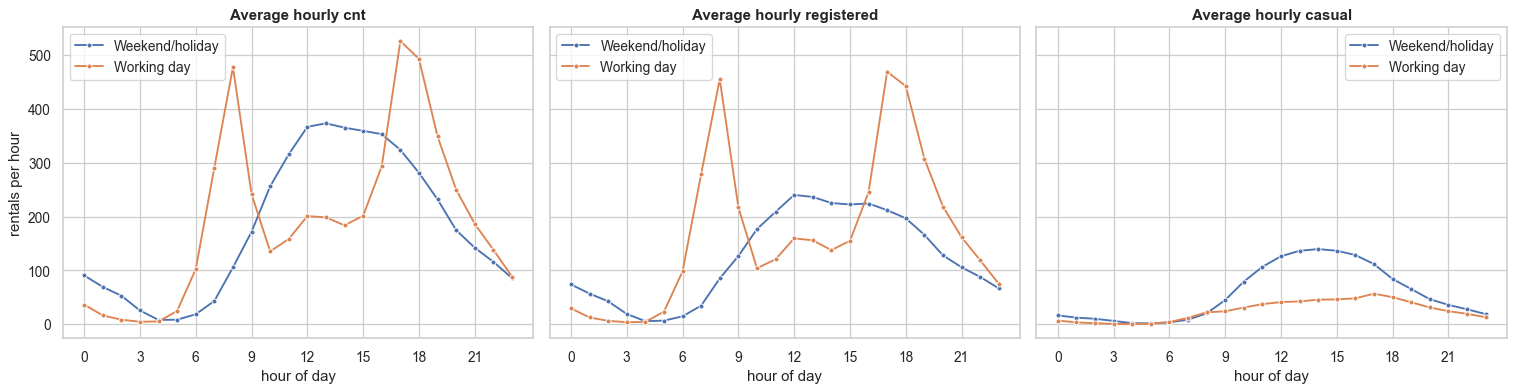

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, col in zip(axes, ["cnt", "registered", "casual"]):
    sns.lineplot(data=hour, x="hr", y=col, hue="day_type", ax=ax, errorbar=None, marker="o", ms=4)
    ax.set(title=f"Average hourly {col}", xlabel="hour of day", ylabel="rentals per hour", xticks=range(0, 24, 3))
    ax.legend(title="")
plt.tight_layout(); plt.show()

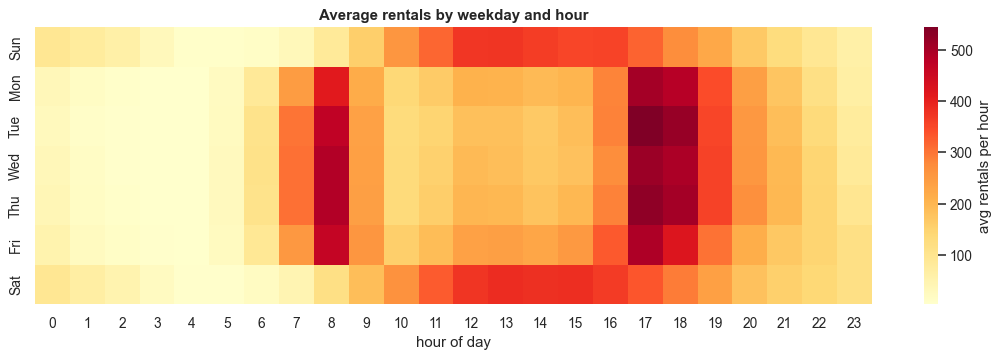

In [13]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
pivot = hour.pivot_table(index="weekday", columns="hr", values="cnt", aggfunc="mean")
pivot.index = days
plt.figure(figsize=(15, 4))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "avg rentals per hour"})
plt.title("Average rentals by weekday and hour"); plt.xlabel("hour of day"); plt.ylabel("")
plt.show()

### 5d. Weather and season
Bad weather cuts demand sharply. Temperature has a strong, roughly linear-then-flattening effect. Heavy weather (category 4) occurs in only 3 hours, so it can't be modelled reliably on its own.

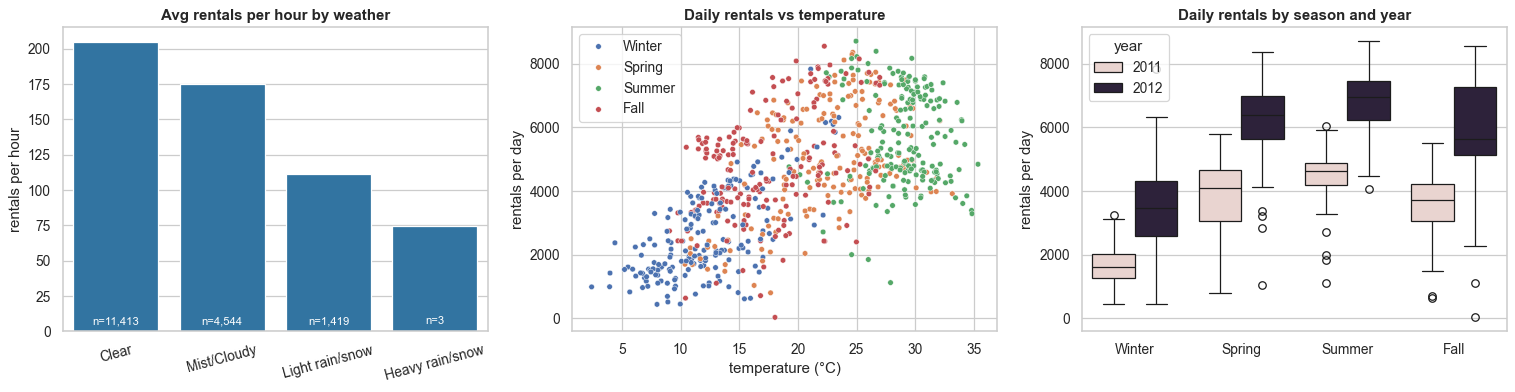

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
order = list(weather_map.values())
sns.barplot(data=hour, x="weather", y="cnt", order=order, ax=axes[0], errorbar=None, color="tab:blue")
counts = hour.weather.value_counts()
for i, w in enumerate(order):
    axes[0].text(i, 5, f"n={counts.get(w, 0):,}", ha="center", color="white", fontsize=9)
axes[0].set(title="Avg rentals per hour by weather", xlabel="", ylabel="rentals per hour")
axes[0].tick_params(axis="x", rotation=15)

sns.scatterplot(data=day, x="temp_c", y="cnt", hue="season_name", ax=axes[1], s=20,
                hue_order=list(season_map.values()))
axes[1].set(title="Daily rentals vs temperature", xlabel="temperature (°C)", ylabel="rentals per day")
axes[1].legend(title="")

sns.boxplot(data=day, x="season_name", y="cnt", hue="year", order=list(season_map.values()), ax=axes[2])
axes[2].set(title="Daily rentals by season and year", xlabel="", ylabel="rentals per day")
plt.tight_layout(); plt.show()

### 5e. Distribution and correlations
Hourly rentals are heavily **right-skewed** (median ≈ 142, max 977), so a log transform or a count-aware model is worth considering. `temp` and `atemp` are almost perfectly correlated, so only one should be kept.

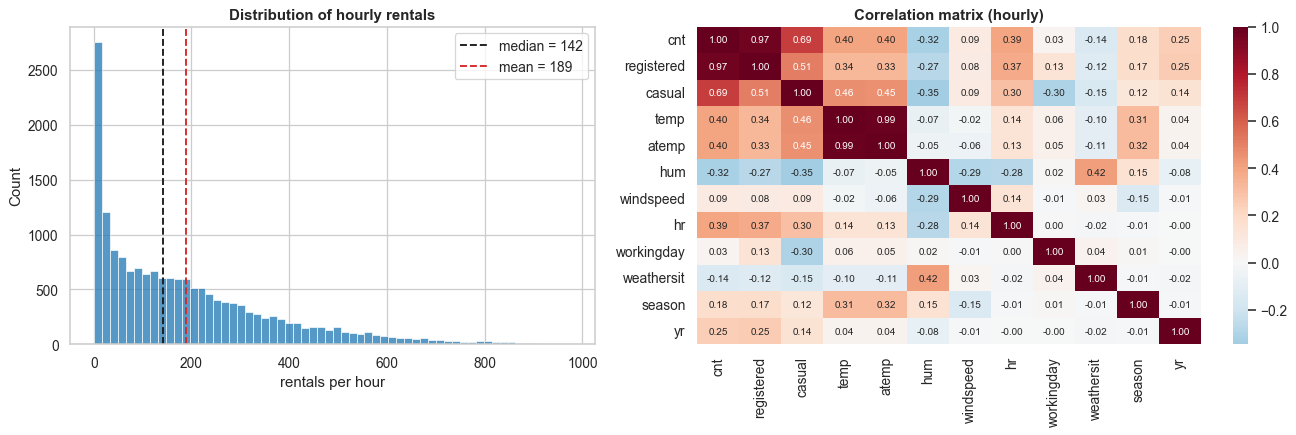

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.histplot(hour.cnt, bins=60, ax=axes[0], color="tab:blue")
axes[0].axvline(hour.cnt.median(), color="k", ls="--", label=f"median = {hour.cnt.median():.0f}")
axes[0].axvline(hour.cnt.mean(), color="tab:red", ls="--", label=f"mean = {hour.cnt.mean():.0f}")
axes[0].set(title="Distribution of hourly rentals", xlabel="rentals per hour"); axes[0].legend()

cols = ["cnt", "registered", "casual", "temp", "atemp", "hum", "windspeed", "hr", "workingday", "weathersit", "season", "yr"]
sns.heatmap(hour[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title("Correlation matrix (hourly)")
plt.tight_layout(); plt.show()

### 5f. Peak vs. typical demand: why bikes sit idle
If the fleet is big enough for the busiest hour, how busy is it the rest of the time? For each day, compare the peak hour with the average hour. A high ratio means most of the fleet is idle outside peaks.

Only 25% of hours reach even half of the 95th-percentile demand.


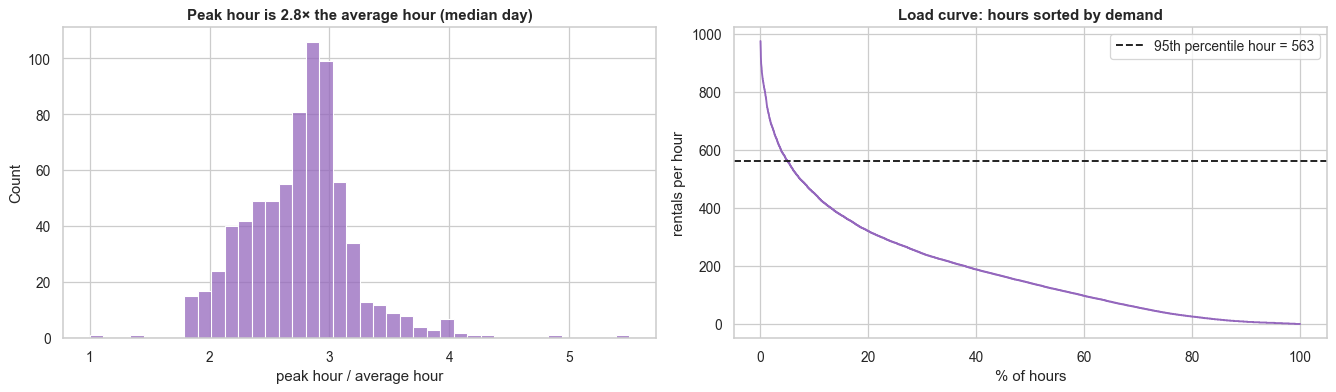

In [16]:
daily_hours = hour.groupby("dteday").cnt.agg(peak="max", avg="mean")
daily_hours["peak_to_avg"] = daily_hours.peak / daily_hours.avg
p95 = hour.cnt.quantile(0.95)
share_above = (hour.cnt > 0.5 * p95).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(daily_hours.peak_to_avg, bins=40, ax=axes[0], color="tab:purple")
axes[0].set(title=f"Peak hour is {daily_hours.peak_to_avg.median():.1f}× the average hour (median day)",
            xlabel="peak hour / average hour")

sorted_cnt = np.sort(hour.cnt.values)[::-1]
axes[1].plot(np.arange(len(sorted_cnt)) / len(sorted_cnt) * 100, sorted_cnt, color="tab:purple")
axes[1].axhline(p95, color="k", ls="--", label=f"95th percentile hour = {p95:.0f}")
axes[1].set(title="Load curve: hours sorted by demand", xlabel="% of hours", ylabel="rentals per hour")
axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Only {share_above:.0%} of hours reach even half of the 95th-percentile demand.")

## 6. Key takeaways

1. **Clean but incomplete.** There are no nulls or duplicates, and `cnt = casual + registered` always holds. But 165 hours are missing (mostly zero-rental night hours), `windspeed = 0` is really missing data, `hum = 0` is a sensor gap, and the readme's season labels are shifted by one (code 1 is winter).
2. **Strong growth.** 2012 had about 65 % more rentals than 2011, so any model must account for the trend (`yr`).
3. **Members dominate.** About 81 % of rentals are by registered users, who drive the commute peaks.
4. **Demand is very concentrated in time.** On working days there are sharp peaks at 08:00 and 17:00–18:00. On a typical day the peak hour is **2.8×** the average hour, and only **25 %** of hours reach even half of the 95th-percentile demand. A fleet sized for the peak sits largely idle the rest of the day. This explains how *"can't find a bike"* and *"bikes sitting unused"* can both be true.
5. **Weather and season matter.** Rain or snow cuts demand by about half, and warm months roughly double it.

## 7. Limitations: what this data can't tell us

- The data is **city-wide totals per hour**. It has no stations, locations, bike availability or fleet size.
- It records **rentals that happened**, not demand that went unserved. When a rider found no bike, nothing was logged, so peak demand is **understated** (censored).
- So we **can't directly see bikes in the wrong place**. The idea that *"stockouts come from location imbalance, not fleet size"* needs station-level data (dock status, trip origin and destination) to test.

**Next steps:** state a testable hypothesis, build a demand model that estimates the bikes needed at peak, and build the natural-language prototype for the operations manager.